# Exemplo didático baseado em Marins et al. (2021) — C1

**Objetivo:** reproduzir **a etapa de extração dos nove atributos estatísticos por janela** descrita na seção 3.1 de Marins et al. (2021), utilizando o sensor **P-TPT** de uma instância real da **classe 2** no **Petrobras 3W 2.0.0**.

**Diferença fundamental:** esta atividade é uma **reprodução parcial da metodologia publicada, reimplementada para demonstração**, e não uma execução do código original dos autores, nem reprodução de suas métricas de classificação (não há Random Forest treinada nesta atividade). O artigo usa uma versão anterior do banco.

**Referência:** Marins et al. (2021), *Fault detection and classification in oil wells and production/service lines using random forest*, Journal of Petroleum Science and Engineering, 197, 107879, DOI:10.1016/j.petrol.2020.107879.

**Arquivo de exemplo escolhido:** `dataset/2/WELL-00002_20131104004101.parquet` (classe 2, origem real; consta no manifesto de treinamento da V3).

Arquivo: WELL-00002_20131104004101.parquet
Dimensoes: (12721, 29)
Colunas: ['ABER-CKGL', 'ABER-CKP', 'ESTADO-DHSV', 'ESTADO-M1', 'ESTADO-M2', 'ESTADO-PXO', 'ESTADO-SDV-GL', 'ESTADO-SDV-P', 'ESTADO-W1', 'ESTADO-W2', 'ESTADO-XO', 'P-ANULAR', 'P-JUS-BS', 'P-JUS-CKGL', 'P-JUS-CKP', 'P-MON-CKGL', 'P-MON-CKP', 'P-MON-SDV-P', 'P-PDG', 'PT-P', 'P-TPT', 'QBS', 'QGL', 'T-JUS-CKP', 'T-MON-CKP', 'T-PDG', 'T-TPT', 'class', 'state']
Janelas validas: 147
Nove atributos estatisticos por janela:
     media  desvio_padrao  assimetria  curtose_excesso     minimo  quartil_25    mediana  quartil_75     maximo
18826442.8       5031.786      -0.872           -0.494 18814780.0  18823007.5 18828245.0  18830317.5 18832400.0
18827218.7       3174.130      -0.036           -1.233 18821760.0  18824502.5 18827245.0  18829987.5 18832400.0
18821703.9       3215.375       0.000           -1.200 18816220.0  18818962.5 18821705.0  18824447.5 18827190.0
18816765.2       2633.623       0.165           -1.108 18812450.0  1

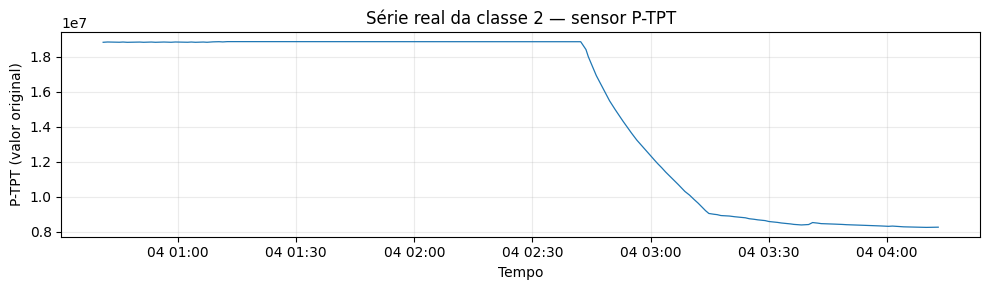

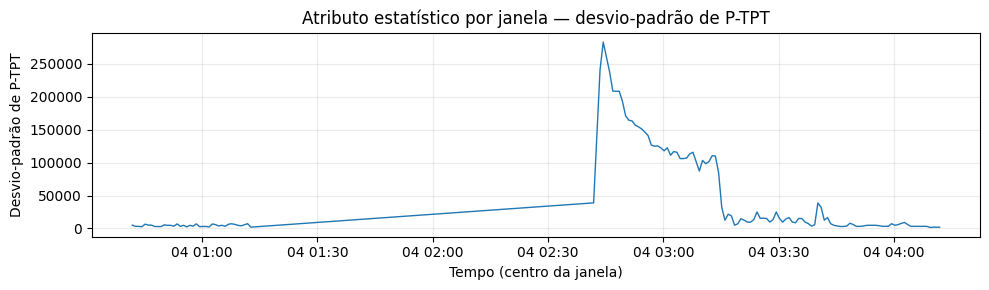

CONCLUIDO: demonstracao de extracao de atributos por janela.
NAO e reproducao integral do artigo e NAO e classificacao treinada.


In [2]:
# C1 — demonstração da extração de atributos proposta em Marins et al. (2021)
# 9 atributos por janela de 100 amostras, deslocamento de 50 amostras.
# Apenas EXTRAÇÃO de atributos: não treina Random Forest nem calcula desempenho.

import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy.stats import skew, kurtosis

url = ('https://raw.githubusercontent.com/petrobras/3W/main/dataset/2/'
       'WELL-00002_20131104004101.parquet')
resposta = requests.get(url, timeout=45)
resposta.raise_for_status()
if resposta.content[:4] != b'PAR1':
    raise RuntimeError('O download nao parece ser um arquivo Parquet valido.')

df = pd.read_parquet(io.BytesIO(resposta.content))
print('Arquivo: WELL-00002_20131104004101.parquet')
print('Dimensoes:', df.shape)
print('Colunas:', list(df.columns))

sensor = 'P-TPT'
if sensor not in df.columns:
    raise KeyError(f'O sensor {sensor} nao foi encontrado neste arquivo.')

serie = pd.to_numeric(df[sensor], errors='coerce')
N, passo = 100, 50
linhas = []

for inicio in range(0, len(serie)-N+1, passo):
    janela = serie.iloc[inicio:inicio+N]
    if janela.isna().any():
        continue  # Não fabricar medições ausentes para este exemplo.
    x = janela.to_numpy(dtype=float)
    if not np.isfinite(x).all() or np.std(x) <= 1e-12:
        continue  # Assimetria e curtose nao definidas em janelas constantes.
    linhas.append({
        'indice_inicio': inicio,
        'tempo_central': df.index[inicio+N//2],
        'media': float(np.mean(x)),
        'desvio_padrao': float(np.std(x, ddof=1)),
        'assimetria': float(skew(x, bias=True)),
        'curtose_excesso': float(kurtosis(x, fisher=True, bias=True)),
        'minimo': float(np.min(x)),
        'quartil_25': float(np.quantile(x, 0.25)),
        'mediana': float(np.median(x)),
        'quartil_75': float(np.quantile(x, 0.75)),
        'maximo': float(np.max(x)),
    })

atributos_marins = pd.DataFrame(linhas)
assert len(atributos_marins) > 0, 'Nenhuma janela valida encontrada.'
print(f'Janelas validas: {len(atributos_marins)}')
print('Nove atributos estatisticos por janela:')
colunas_9 = ['media','desvio_padrao','assimetria','curtose_excesso',
             'minimo','quartil_25','mediana','quartil_75','maximo']
print(atributos_marins[colunas_9].head(5).round(3).to_string(index=False))

plt.figure(figsize=(10, 3))
plt.plot(df.index, serie, linewidth=0.9)
plt.title('Série real da classe 2 — sensor P-TPT')
plt.xlabel('Tempo')
plt.ylabel('P-TPT (valor original)')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 3))
plt.plot(atributos_marins['tempo_central'], atributos_marins['desvio_padrao'], linewidth=1)
plt.title('Atributo estatístico por janela — desvio-padrão de P-TPT')
plt.xlabel('Tempo (centro da janela)')
plt.ylabel('Desvio-padrão de P-TPT')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print('CONCLUIDO: demonstracao de extracao de atributos por janela.')
print('NAO e reproducao integral do artigo e NAO e classificacao treinada.')